## 04c. Analysis by Label, TF-IDF and Visualizations

### Read-In Data and Load Packages

In [1]:
import numpy as np
import pandas as pd               
import plotnine
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
import re

In [2]:
df_rules = pd.read_csv("../data/fr_rules_labels_metadata.csv")

In [3]:
df_rules['gemini_label'].value_counts()

gemini_label
passing mention    137
promote             49
regulate            37
Name: count, dtype: int64

In [4]:
df_rules['gemini_label'].value_counts(normalize=True) * 100

gemini_label
passing mention    61.434978
promote            21.973094
regulate           16.591928
Name: proportion, dtype: float64

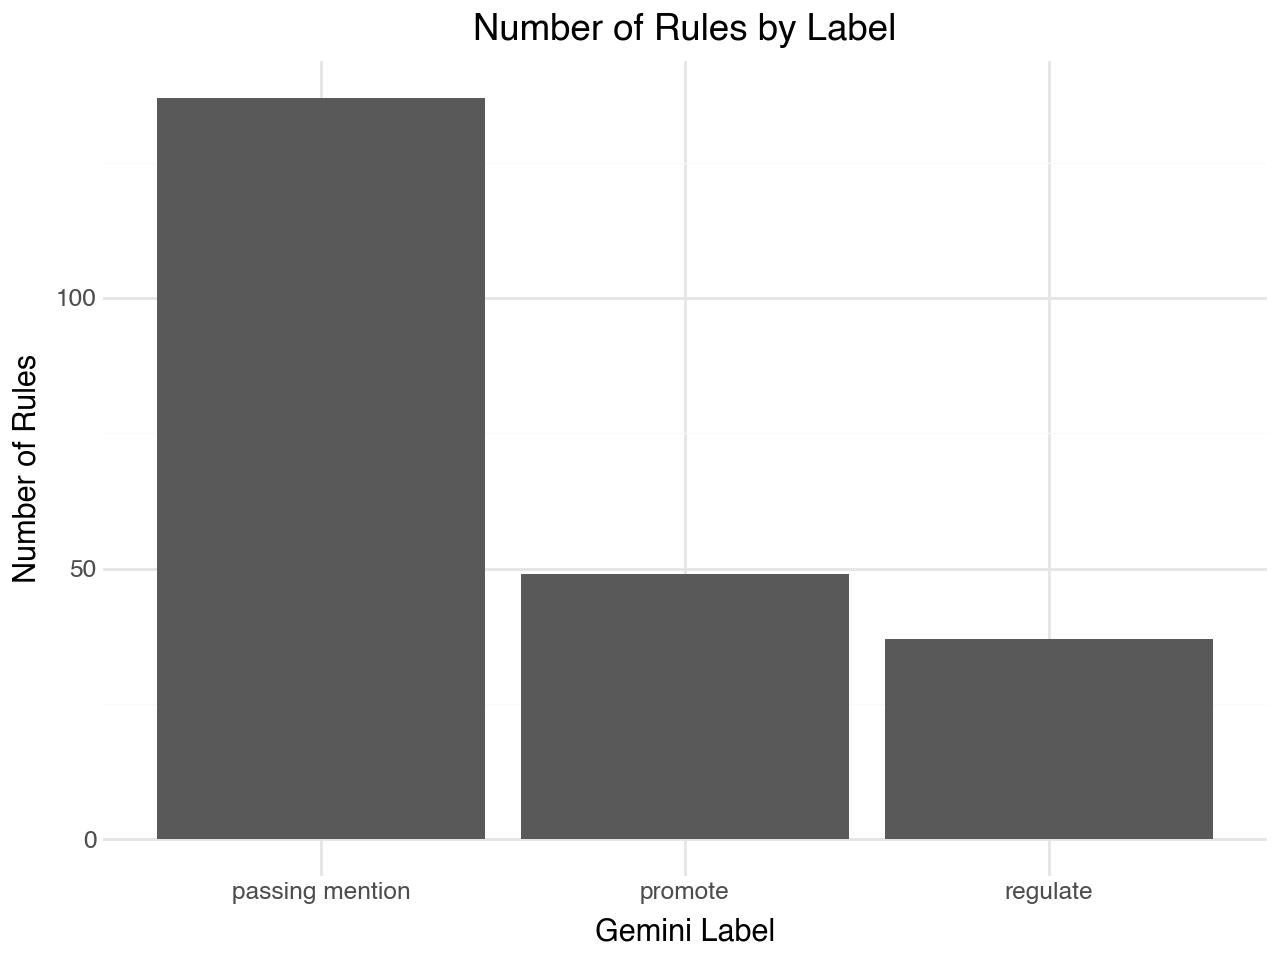

In [5]:
plot1 = (plotnine.ggplot(df_rules, plotnine.aes(x='gemini_label'))
         + plotnine.geom_bar()
         + plotnine.labs(title='Number of Rules by Label',
                         x='Gemini Label',
                         y='Number of Rules')
         + plotnine.theme_minimal())
plot1

In our dataset, 137 of 223 rules (61%) are labeled passing mention, 49 (22%) are labeled promote, and 37 (17%) are labeled regulate.

### TF-IDF by Label

In [6]:
#functions from HW4
def clean_post(text):
    """Lowercase the text, remove most punctuation, and tidy up spaces."""
    lowered = str(text).lower()
    # Replace anything that isn't a-z, 0-9, a space, an apostrophe, or a hyphen with a space.
    no_punctuation = re.sub(r"[^a-z0-9\s'-]", " ", lowered)
    # Turn runs of spaces into a single space, and trim both ends.
    return re.sub(r"\s+", " ", no_punctuation).strip()

def compare_groups(vectorizer, matrix, mask_a, mask_b, n=15):
    """Return the words whose average score differs most between two groups of rows."""
    average_a = np.asarray(matrix[mask_a].mean(axis=0)).ravel()
    average_b = np.asarray(matrix[mask_b].mean(axis=0)).ravel()
    difference = pd.DataFrame({
        "term": vectorizer.get_feature_names_out(),
        "difference": average_a - average_b,
    }).sort_values("difference", ascending=False)
    return pd.DataFrame({
        "leans_a": difference["term"].head(n).to_numpy(),
        "leans_b": difference["term"].tail(n)[::-1].to_numpy(),
    })

custom_stop_words = list(ENGLISH_STOP_WORDS | {"2019", "2020", "2021", "2022", "2023", "2024", "2025", "2026", "al", "et"})
project_vectorizer = TfidfVectorizer(stop_words=custom_stop_words, min_df=5)
df_rules["clean_text"] = df_rules["passages"].apply(clean_post)
project_matrix = project_vectorizer.fit_transform(df_rules["clean_text"])

In [7]:
regulate = (df_rules["gemini_label"] == "regulate").to_numpy()
allother_regulate = (df_rules["gemini_label"] != "regulate").to_numpy()
label_terms_regulate = compare_groups(project_vectorizer, project_matrix, regulate, allother_regulate, n=15)
label_terms_regulate.head(15)

,leans_a,leans_b
0,advanced,commenters
1,controls,data
2,items,commenter
3,military,code
4,computing,cms
5,ics,proposed
6,weapons,cpt
7,bis,comments
8,device,available
9,china,time


The words most associated with regulate passages are advanced, controls, items, military, computing, ics, weapons, bis, device, china, fda, action, guidance, entity, and circuits.

In [8]:
promote = (df_rules["gemini_label"] == "promote").to_numpy()
allother_promote = (df_rules["gemini_label"] != "promote").to_numpy()
label_terms_promote = compare_groups(project_vectorizer, project_matrix, promote, allother_promote, n=15)
label_terms_promote.head(15)

,leans_a,leans_b
0,comments,software
1,critical,stated
2,language,commenters
3,program,energy
4,hhs,device
5,individuals,commenter
6,support,use
7,experts,controls
8,priority,consumer
9,moving,information


The words most associated with promote passages are comments, critical, language, program, hhs, individuals, support, experts, priority, moving, education, model, following, commission, and data.

In [9]:
passing_mention = (df_rules["gemini_label"] == "passing mention").to_numpy()
allother_passing_mention = (df_rules["gemini_label"] != "passing mention").to_numpy()
label_terms_passing_mention = compare_groups(project_vectorizer, project_matrix, passing_mention, allother_passing_mention, n=15)
label_terms_passing_mention.head(15)

,leans_a,leans_b
0,commenters,advanced
1,commenter,items
2,stated,critical
3,energy,commission
4,https,fda
5,available,ics
6,pe,comments
7,demand,computing
8,methodology,hhs
9,disclosure,cfr


The words most associated with passing mention passages are commenters, commenter, stated, energy, https, available, pe, demand, methodology, disclosure, act, centers, digital, companies, and market. The top two words relate to public comments, which we look at next.

### Public Comments in Passing Mention Passages

In [10]:
comment_vector = ["comment", "comments", "commented", "commenting", "commentary", "commentaries", "commented-on", "commented-upon", "commented-about", "commented-within"]
df_rules["contains_comment"] = df_rules["passages"].str.contains('|'.join(comment_vector), case=False, na=False)

In [11]:
df_passing_mention = df_rules[df_rules["gemini_label"] == "passing mention"]

pd.crosstab(df_passing_mention['administration'],
            df_passing_mention['contains_comment'],
            margins=True, margins_name='Total')

contains_comment,False,True,Total
administration,,,
Biden,32,34,66
Trump I,7,12,19
Trump II,18,34,52
Total,57,80,137


In [12]:
pd.crosstab(df_passing_mention['administration'],
            df_passing_mention['contains_comment'],
            normalize='index') * 100

contains_comment,False,True
administration,,
Biden,48.484848,51.515152
Trump I,36.842105,63.157895
Trump II,34.615385,65.384615


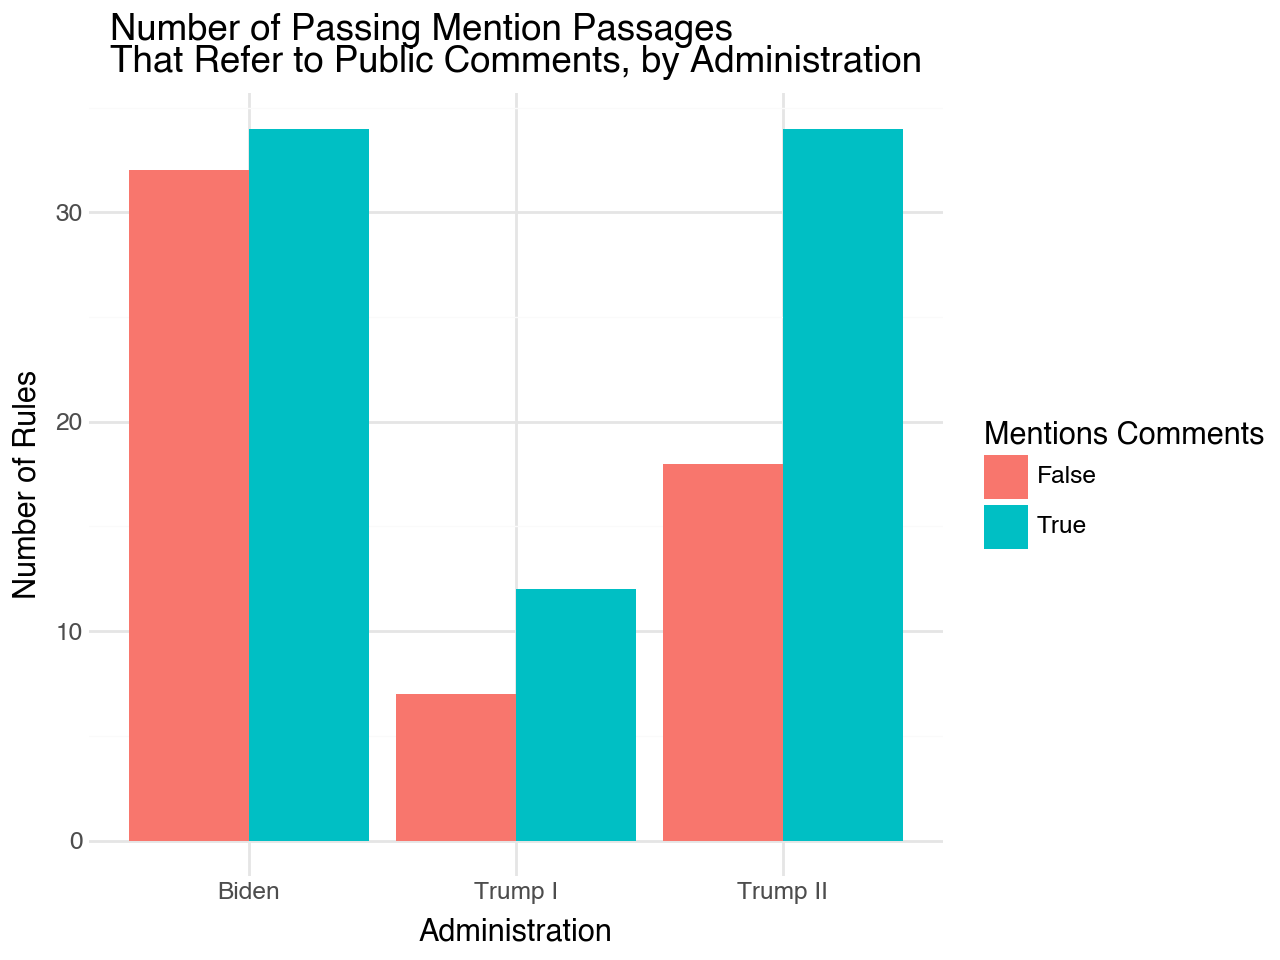

In [19]:
plot2 = (plotnine.ggplot(df_passing_mention, plotnine.aes(x='administration', fill='contains_comment'))
         + plotnine.geom_bar(position='dodge')
         + plotnine.labs(title='Number of Passing Mention Passages\nThat Refer to Public Comments, by Administration',
                         x='Administration',
                         y='Number of Rules',
                         fill='Mentions Comments')
         + plotnine.theme_minimal())
plot2


Among passing mention passages, 34 of 66 (52%) under Biden, 12 of 19 (63%) under Trump I, and 34 of 52 (65%) under Trump II refer to public comments.

In all three administrations, most passing mention passages refer to public comments. Biden has the most passing mention passages overall (66), and Trump II has the highest share that refer to public comments (65%).

In [14]:
df_label_matched = df_passing_mention.copy()
df_label_matched[ 'matched_artificial_intelligence' ] = df_label_matched[ 'matched_terms' ].str.contains('artificial intelligence', case=False, na=False)
df_label_matched[ 'matched_machine_learning' ] = df_label_matched[ 'matched_terms' ].str.contains('machine learning', case=False, na=False)

In [15]:
df_ai_true = df_label_matched[df_label_matched['matched_artificial_intelligence'] == True]

pd.crosstab(df_ai_true['administration'],
            df_ai_true['contains_comment'],
            margins=True, margins_name='Total')

contains_comment,False,True,Total
administration,,,
Biden,26,33,59
Trump I,3,8,11
Trump II,16,31,47
Total,45,72,117


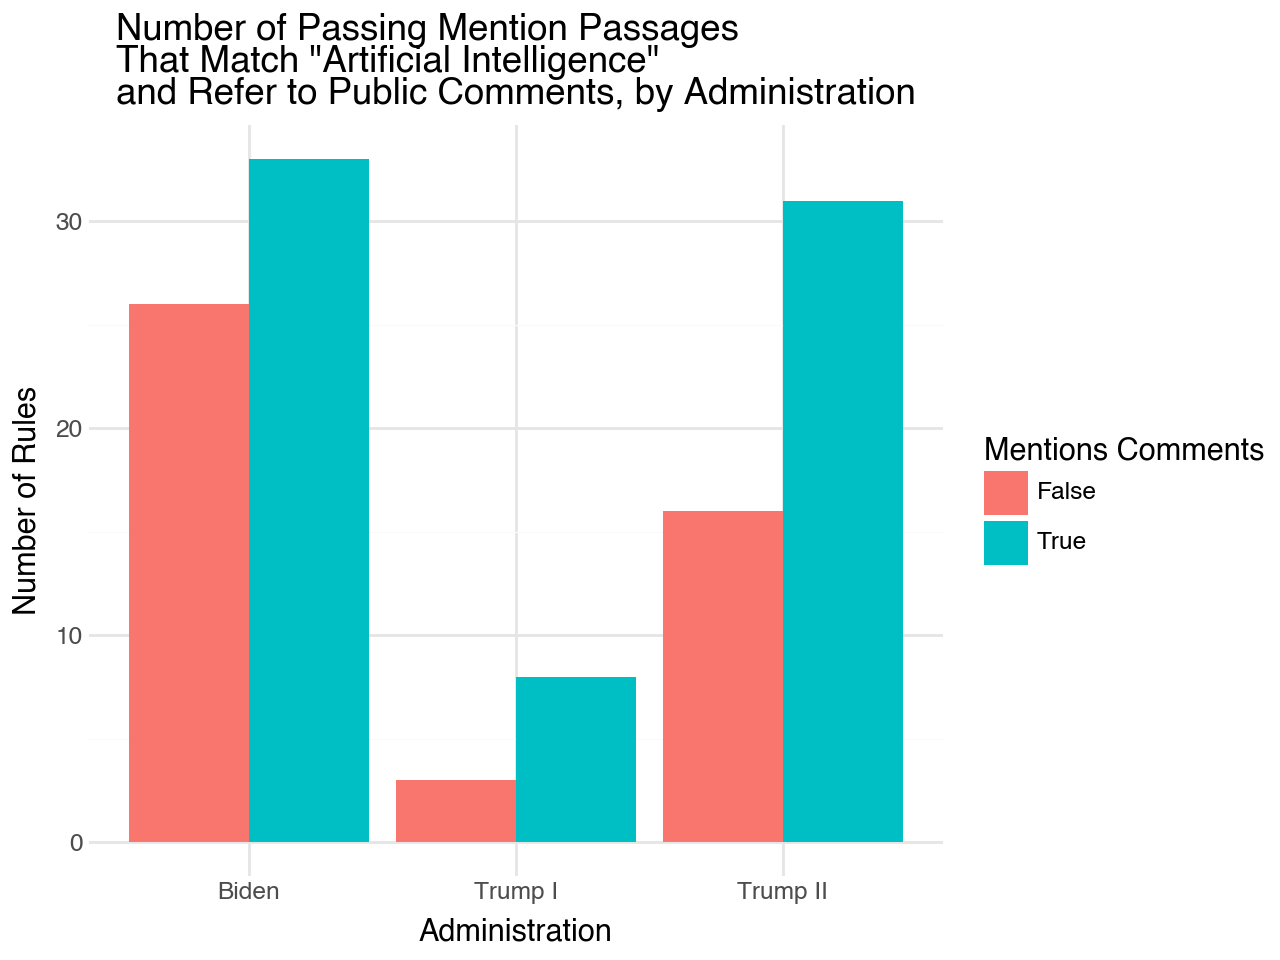

In [16]:
plot3a = (plotnine.ggplot(df_ai_true, plotnine.aes(x='administration', fill='contains_comment'))
          + plotnine.geom_bar(position='dodge')
          + plotnine.labs(title='Number of Passing Mention Passages\nThat Match "Artificial Intelligence"\nand Refer to Public Comments, by Administration',
                          x='Administration',
                          y='Number of Rules',
                          fill='Mentions Comments')
          + plotnine.theme_minimal())
plot3a

Among passing mention passages that match "artificial intelligence," 33 of 59 (56%) under Biden, 8 of 11 (73%) under Trump I, and 31 of 47 (66%) under Trump II refer to public comments.

In all three administrations, most of these passages refer to public comments. Biden has the most passages (59), and Trump I has the highest share that refer to public comments (73%).

In [17]:
df_ml_true = df_label_matched[df_label_matched['matched_machine_learning'] == True]

pd.crosstab(df_ml_true['administration'],
            df_ml_true['contains_comment'],
            margins=True, margins_name='Total')
        

contains_comment,False,True,Total
administration,,,
Biden,17,17,34
Trump I,5,5,10
Trump II,2,11,13
Total,24,33,57


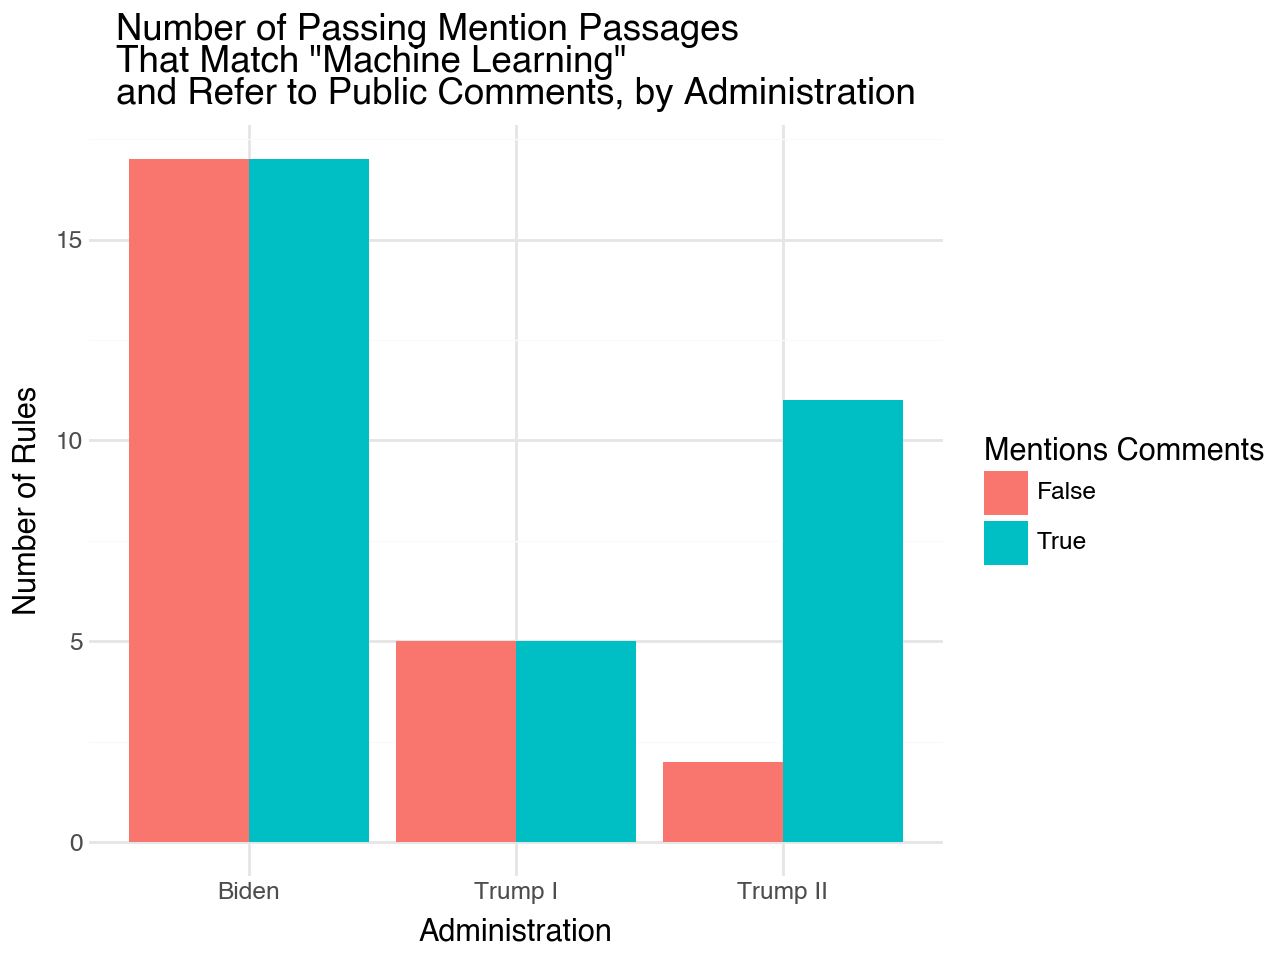

In [18]:
plot3b = (plotnine.ggplot(df_ml_true, plotnine.aes(x='administration', fill='contains_comment'))
          + plotnine.geom_bar(position='dodge')
          + plotnine.labs(title='Number of Passing Mention Passages\nThat Match "Machine Learning"\nand Refer to Public Comments, by Administration',
                          x='Administration',
                          y='Number of Rules',
                          fill='Mentions Comments')
          + plotnine.theme_minimal())
plot3b


Among passing mention passages that match "machine learning," 17 of 34 (50%) under Biden, 5 of 10 (50%) under Trump I, and 11 of 13 (85%) under Trump II refer to public comments.

Biden has the most of these passages (34), and Trump I has the fewest (10). Trump II has the highest share that refer to public comments (85%).